# Fundamentals of Data Science Assignment

## 1. Introduction
This notebook presents the analysis of a mock census dataset to support evidence-based recommendations for local government planning. The analysis includes data cleaning, exploratory data analysis (EDA), statistical analysis, and data visualisation to inform decisions regarding infrastructure development and public investment

## 2. Project Objectives

- To clean and prepare the mock census dataset for analysis.
- To explore the demographic characteristics of the town using exploratory data analysis (EDA).
- To identify demographic patterns and trends relating to population, housing, employment, religion, and other relevant variables.
- To use the findings to recommend an appropriate development for the unoccupied plot of land.
- To recommend an investment priority based on evidence from the census data.

## 3. Import the libraries

In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 4. Load the Dataset

In [232]:
data = pd.read_excel("T2_A24_census0.xlsx")
data
#load the excel file and convert to a dataframe

,House Number,Street,First Name,Surname,Age,Relationship to Head of House,Marital Status,Gender,Occupation,Infirmity,Religion
0,1,Monk Flats,Lisa,Gray,63,Head,Married,Female,Product manager,NaN,No Religion
1,1,Monk Flats,Maurice,Gray,66,Husband,Married,Male,"Surveyor, land/geomatics",NaN,No Religion
2,2,Monk Flats,Brett,Bradley,45,Head,Divorced,Male,Waste management officer,NaN,Christian
3,3,Monk Flats,Denise,Butler,69,Head,Married,Female,"Retired Programme researcher, broadcasting/fil...",NaN,Christian
4,3,Monk Flats,Conor,Butler,71,Husband,Married,Male,"Retired Therapist, speech and language",NaN,No Religion
...,...,...,...,...,...,...,...,...,...,...,...
7822,1,Dickinson Fort,Stephen,Baxter,28,Son,Divorced,Male,"Surveyor, building control",NaN,No Religion
7823,1,Dickinson Fort,Adrian,Baxter,25,Son,Single,Male,Hydrogeologist,NaN,No Religion
7824,1,Dickinson Fort,Christian,Baxter,24,Son,Divorced,Male,Risk analyst,NaN,No Religion
7825,1,Dickinson Fort,Lorraine,Baxter,21,Daughter,Single,Female,University Student,NaN,No Religion


In [174]:
data

,House Number,Street,First Name,Surname,Age,Relationship to Head of House,Marital Status,Gender,Occupation,Infirmity,Religion
0,1,Monk Flats,Lisa,Gray,63,Head,Married,Female,Product manager,NaN,No Religion
1,1,Monk Flats,Maurice,Gray,66,Husband,Married,Male,"Surveyor, land/geomatics",NaN,No Religion
2,2,Monk Flats,Brett,Bradley,45,Head,Divorced,Male,Waste management officer,NaN,Christian
3,3,Monk Flats,Denise,Butler,69,Head,Married,Female,"Retired Programme researcher, broadcasting/fil...",NaN,Christian
4,3,Monk Flats,Conor,Butler,71,Husband,Married,Male,"Retired Therapist, speech and language",NaN,No Religion
...,...,...,...,...,...,...,...,...,...,...,...
7822,1,Dickinson Fort,Stephen,Baxter,28,Son,Divorced,Male,"Surveyor, building control",NaN,No Religion
7823,1,Dickinson Fort,Adrian,Baxter,25,Son,Single,Male,Hydrogeologist,NaN,No Religion
7824,1,Dickinson Fort,Christian,Baxter,24,Son,Divorced,Male,Risk analyst,NaN,No Religion
7825,1,Dickinson Fort,Lorraine,Baxter,21,Daughter,Single,Female,University Student,NaN,No Religion


## 4. Data Inspection

In [175]:
data.head()
#this provides the first 5 rows of the dataframe

,House Number,Street,First Name,Surname,Age,Relationship to Head of House,Marital Status,Gender,Occupation,Infirmity,Religion
0,1,Monk Flats,Lisa,Gray,63,Head,Married,Female,Product manager,NaN,No Religion
1,1,Monk Flats,Maurice,Gray,66,Husband,Married,Male,"Surveyor, land/geomatics",NaN,No Religion
2,2,Monk Flats,Brett,Bradley,45,Head,Divorced,Male,Waste management officer,NaN,Christian
3,3,Monk Flats,Denise,Butler,69,Head,Married,Female,"Retired Programme researcher, broadcasting/fil...",NaN,Christian
4,3,Monk Flats,Conor,Butler,71,Husband,Married,Male,"Retired Therapist, speech and language",NaN,No Religion


In [176]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7827 entries, 0 to 7826
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   House Number                   7827 non-null   int64 
 1   Street                         7827 non-null   object
 2   First Name                     7827 non-null   object
 3   Surname                        7819 non-null   object
 4   Age                            7827 non-null   int64 
 5   Relationship to Head of House  7276 non-null   object
 6   Marital Status                 6015 non-null   object
 7   Gender                         7827 non-null   object
 8   Occupation                     7827 non-null   object
 9   Infirmity                      103 non-null    object
 10  Religion                       6895 non-null   object
dtypes: int64(2), object(9)
memory usage: 672.8+ KB


In [177]:
data.describe()
#this provides the statistical analysis of the data

,House Number,Age
count,7827.000000,7827.000000
mean,25.586687,35.839785
std,27.247706,21.480660
min,1.000000,0.000000
25%,8.000000,18.000000
50%,18.000000,35.000000
75%,33.000000,51.000000
max,176.000000,112.000000


## 5. Data Cleaning

##### Check for missing values

In [178]:
data.isnull().sum()

House Number                        0
Street                              0
First Name                          0
Surname                             8
Age                                 0
Relationship to Head of House     551
Marital Status                   1812
Gender                              0
Occupation                          0
Infirmity                        7724
Religion                          932
dtype: int64

##### Fill empty cells with "Unknown"

In [179]:
data['Surname'] = data['Surname'].fillna("Unknown")

##### Fill empty cells in the Relationship to Head of Housewith the mode

In [234]:
#Fill missing values in the 'Relationship to Head of House' column with the most frequent value (mode)
data['Relationship to Head of House'] = data['Relationship to Head of House'].fillna(data['Relationship to Head of House'].mode()[0])

##### Check missing marital records for residents under 18 and over 18

In [181]:
under18 = (data.loc[data['Age'] < 18, 'Marital Status'].isna().sum())

over18 = (data.loc[data['Age'] >= 18, 'Marital Status'].isna().sum())

In [235]:
print(under18)
print(over18)
#we have 1812 marital records under 18

1812
0


In [185]:
# Replace missing values with 'No Infirmity'
data['Infirmity'] = data['Infirmity'].fillna("No Infirmity")

##### Marital status is recorded as N/A for residents under 18

In [183]:

data.loc[
    (data['Age'] < 18) & (data['Marital Status'].isna()),
    'Marital Status'
] = 'N/A'

##### Show all the counts of the values in the Infirmity column

In [184]:
data['Infirmity'].value_counts(dropna=False)

Infirmity
NaN                    7724
Unknown Infection        20
Broken Finger            18
Physical Disability      15
Disabled                 11
                         11
Blind                    10
Deaf                     10
Mental Disability         8
Name: count, dtype: int64

In [186]:
# Fill remaining missing religion values using the most common category
religion_mode = data['Religion'].mode()[0]

data['Religion'] = data['Religion'].fillna(religion_mode)

In [187]:
data.isnull().sum()

House Number                     0
Street                           0
First Name                       0
Surname                          0
Age                              0
Relationship to Head of House    0
Marital Status                   0
Gender                           0
Occupation                       0
Infirmity                        0
Religion                         0
dtype: int64

## 6. Exploratory Data Analysis (E.D.A)



After cleaning the dataset, exploratory data analysis was carried out to understand the demographic structure of the town. Univariate analysis was used to examine individual variables, while bivariate analysis was used to look at relationships between two variables.

The analysis focused on age, gender, marital status, occupation, religion, infirmity, household relationships and household size.

##### Total number of children between 0-17

In [229]:
children_0_17 = data.loc[data["Age"].between(0,17)]
print("Residents aged 0-17:", len(children_0_17))

print("Percentage:", round(
    (len(children_0_17)/len(data)
    ) * 100,2), "%")

Residents aged 0-17: 1855
Percentage: 23.7 %


##### Total number of children between 5-17

In [230]:
children_5_17 = data.loc[data["Age"].between(5,17)]
print("Residents aged 5-17:", len(children_5_17))

print("Percentage:", round(
    (len(children_5_17)/len(data)
    ) * 100,2), "%")

Residents aged 5-17: 1378
Percentage: 17.61 %


##### Total number of children between 0-4

In [231]:
children_0_4 = data.loc[data["Age"].between(0,4)]
print("Residents aged 0-4:", len(children_0_4))

print("Percentage:", round(
    (len(children_0_4)/len(data)
    ) * 100,2), "%")

Residents aged 0-4: 477
Percentage: 6.09 %


### Univariate analysis

Age distribution


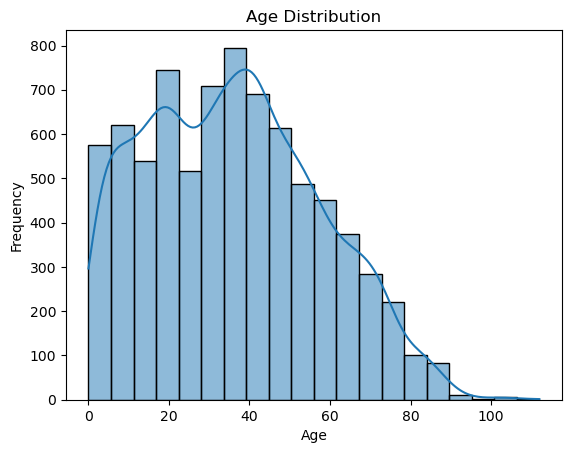

In [188]:

sns.histplot(data=data, x='Age', bins=20, kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

Gender distribution

Text(0, 0.5, 'Count')

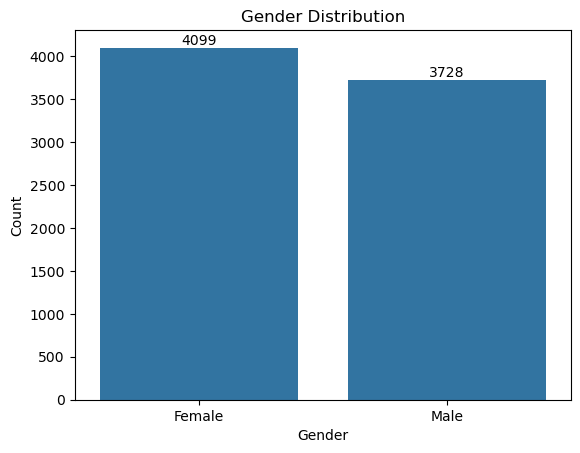

In [189]:
count = sns.countplot(data=data, x='Gender')

for i in count.containers:
    count.bar_label(i)
    
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')

#we have more female than male residents

Marital status distribution

Text(0, 0.5, 'Count')

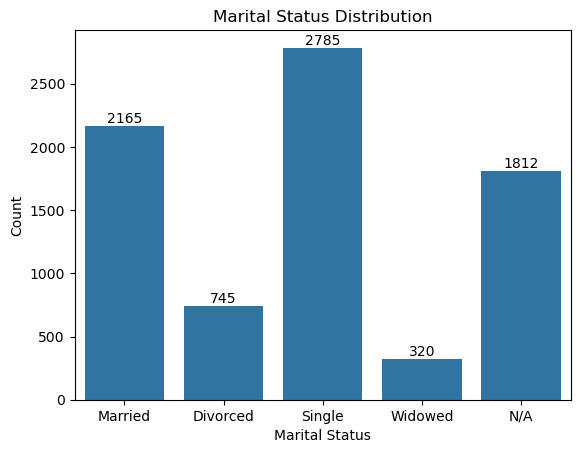

In [190]:
count2 = sns.countplot(data=data, x='Marital Status')

for i in count2.containers:
    count2.bar_label(i)
    
plt.title('Marital Status Distribution')
plt.xlabel('Marital Status')
plt.ylabel('Count')

#we have more residents that are single

Religion distribution

Text(0, 0.5, 'Count')

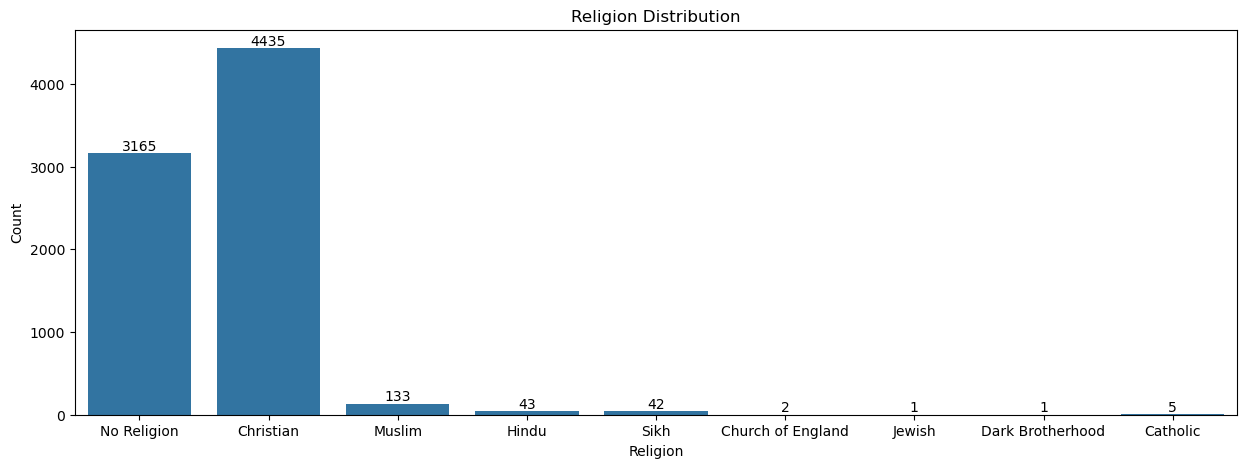

In [191]:
plt.figure(figsize=(15,5))
count3 = sns.countplot(data=data, x='Religion')

for i in count3.containers:
    count3.bar_label(i)
    
plt.title('Religion Distribution')
plt.xlabel('Religion')
plt.ylabel('Count')

#we have more Christians than any other religion

Top 10 occupation

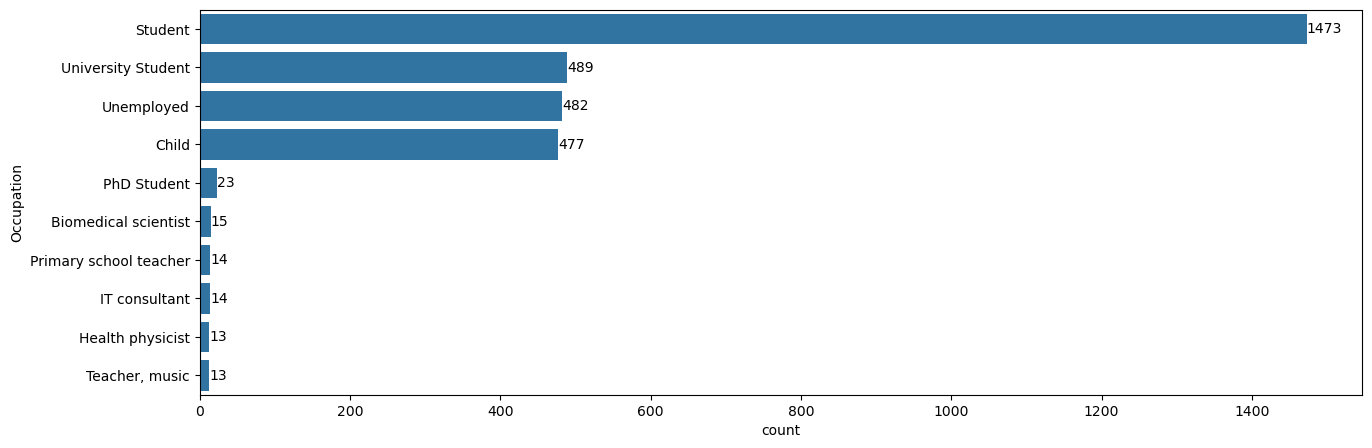

In [192]:
plt.figure(figsize=(15,5))

top_10_occupation = data['Occupation'].value_counts().index[:10]

count4 = sns.countplot(y='Occupation',data=data, order=top_10_occupation)
for i in count4.containers:
    count4.bar_label(i)

#Top 10 occupation with students having the highest number of residents and university students with a total of 489

Distribution of Relationship to Head of House

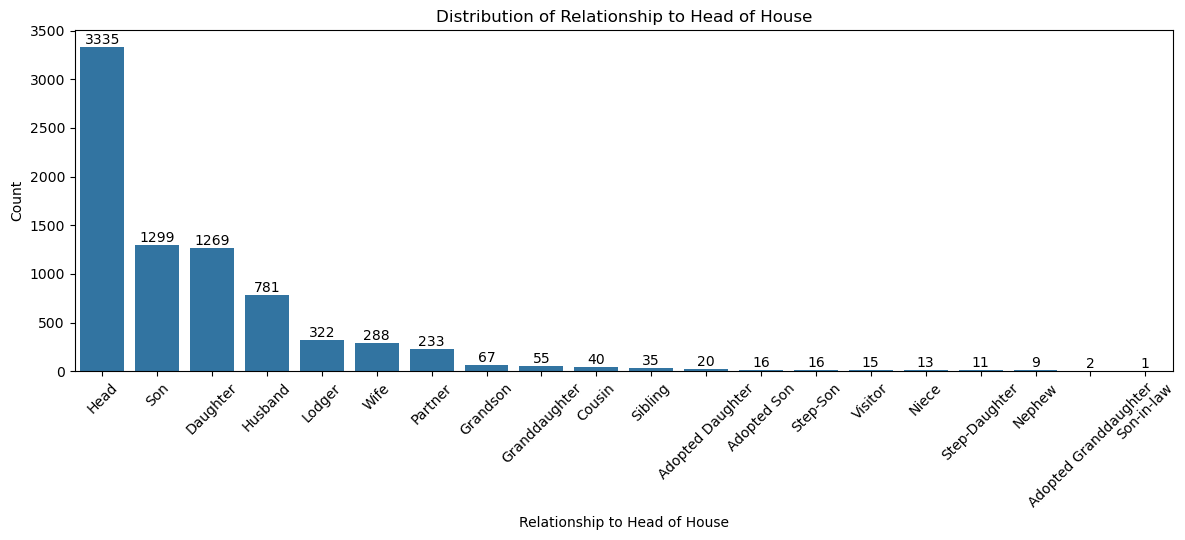

In [193]:
plt.figure(figsize=(12,5.5))

count5 = sns.countplot(x='Relationship to Head of House',
                       data=data,
                       order=data['Relationship to Head of House'].value_counts().index)

for i in count5.containers:
    count5.bar_label(i)

plt.title('Distribution of Relationship to Head of House')
plt.xlabel('Relationship to Head of House')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Distribution of Infirmity

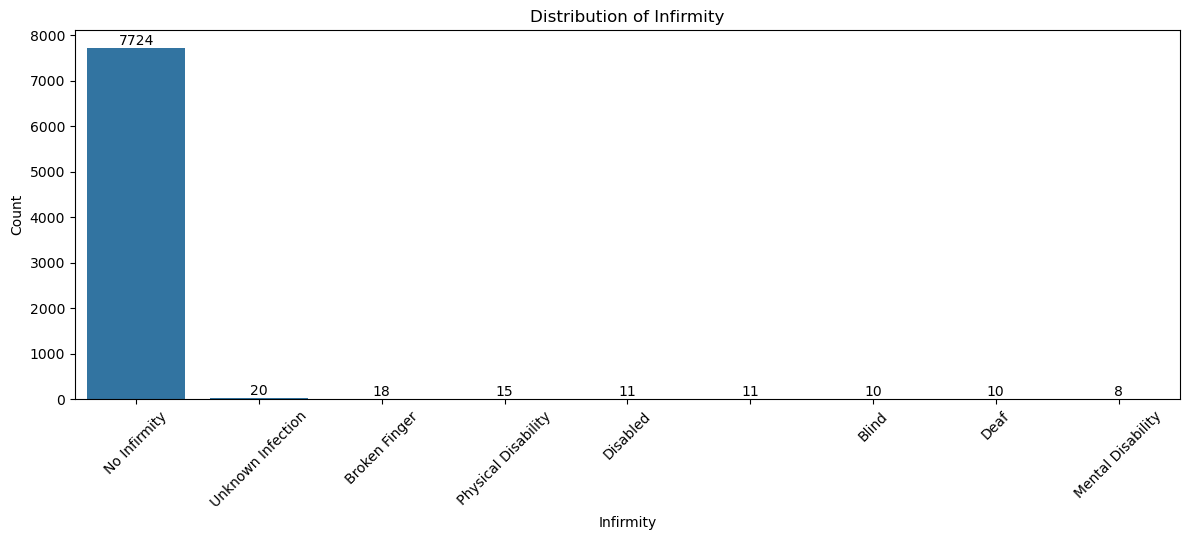

In [194]:
plt.figure(figsize=(12,5.5))

count6 = sns.countplot(x='Infirmity',
                       data=data,
                       order=data['Infirmity'].value_counts().index)

for i in count6.containers:
    count6.bar_label(i)

plt.title('Distribution of Infirmity')
plt.xlabel('Infirmity')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#we have more residents with No infirmity than with Infirmity

##### Exclude "No affirmity" so we can compare the other reported affirmities

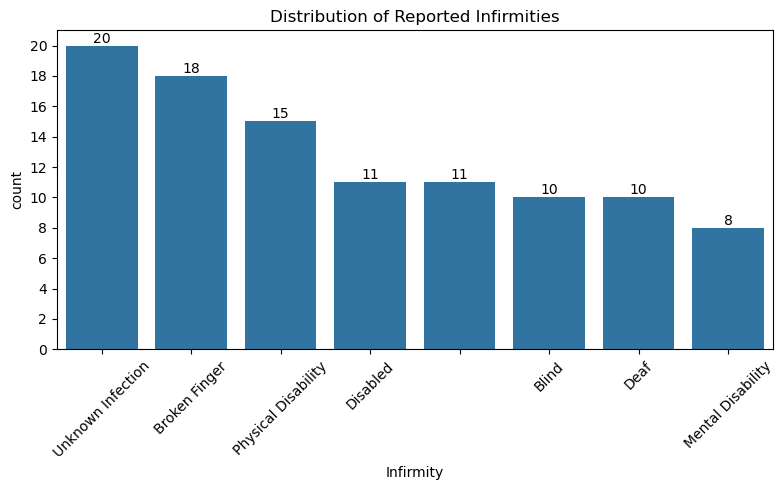

In [195]:
infirmity = data[data['Infirmity'] != 'No Infirmity']

plt.figure(figsize=(8,5))

count7 = sns.countplot(
    data=infirmity,
    x='Infirmity',
    order=infirmity['Infirmity'].value_counts().index
)

for i in count7.containers:
    count7.bar_label(i)

plt.title('Distribution of Reported Infirmities')
plt.xticks(rotation=45)
plt.yticks(range(0, 21, 2))
plt.tight_layout()
plt.show()

##### Age distribution to check for outliers

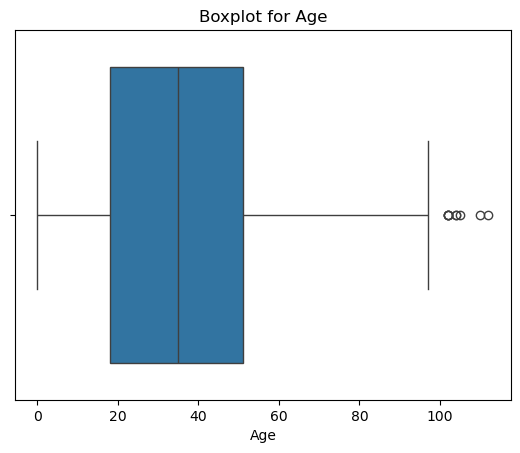

In [196]:
sns.boxplot(x=data['Age'])

plt.title('Boxplot for Age')
plt.show()

#we have outliers above 100, some residents age are above 100

#### Bivariate analysis

Text(0.5, 1.0, 'Box plot for Age and Marital Status')

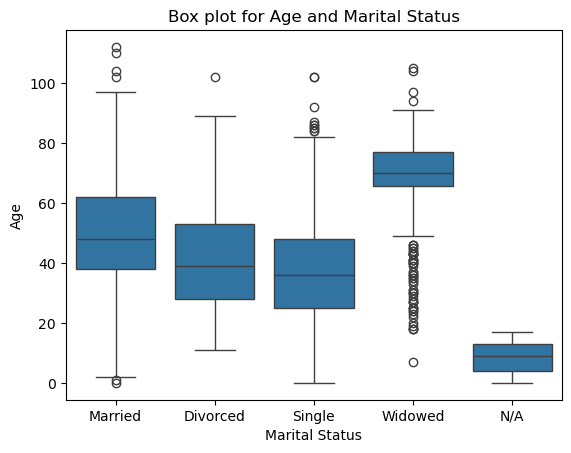

In [197]:
#relationship between 2 variables.
#Does marital status change with age?

sns.boxplot(x="Marital Status", y="Age", data=data)

plt.title("Box plot for Age and Marital Status")

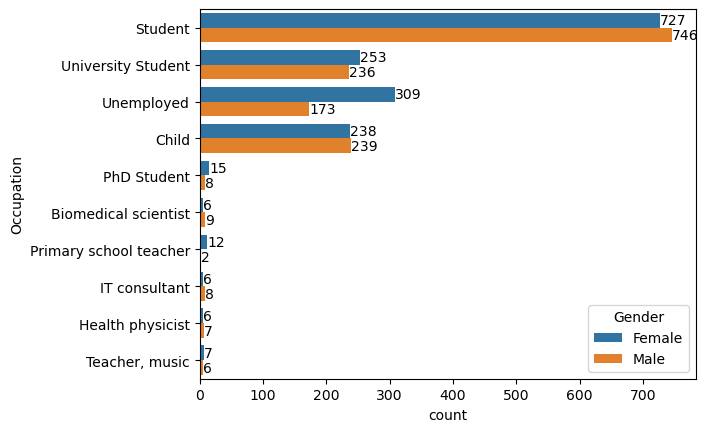

In [198]:
#relationship between Gender and Occupation


count8 = sns.countplot(y="Occupation", data=data, hue="Gender", order=top_10_occupation)
for i in count8.containers:
    count8.bar_label(i)

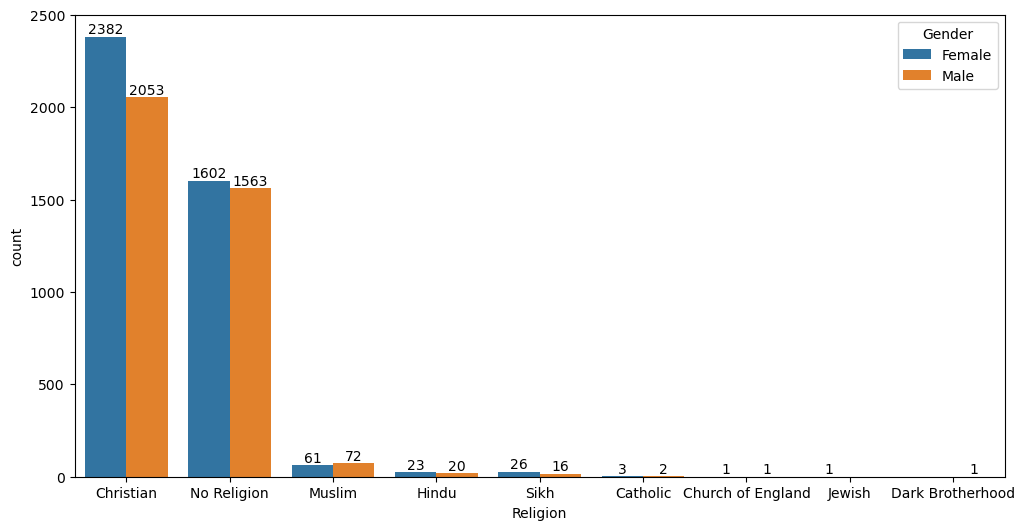

In [199]:
plt.figure(figsize=(12,6))

count9 = sns.countplot(x="Religion", data=data, hue="Gender", order=data["Religion"].value_counts().index)

for i in count9.containers:
    count9.bar_label(i)

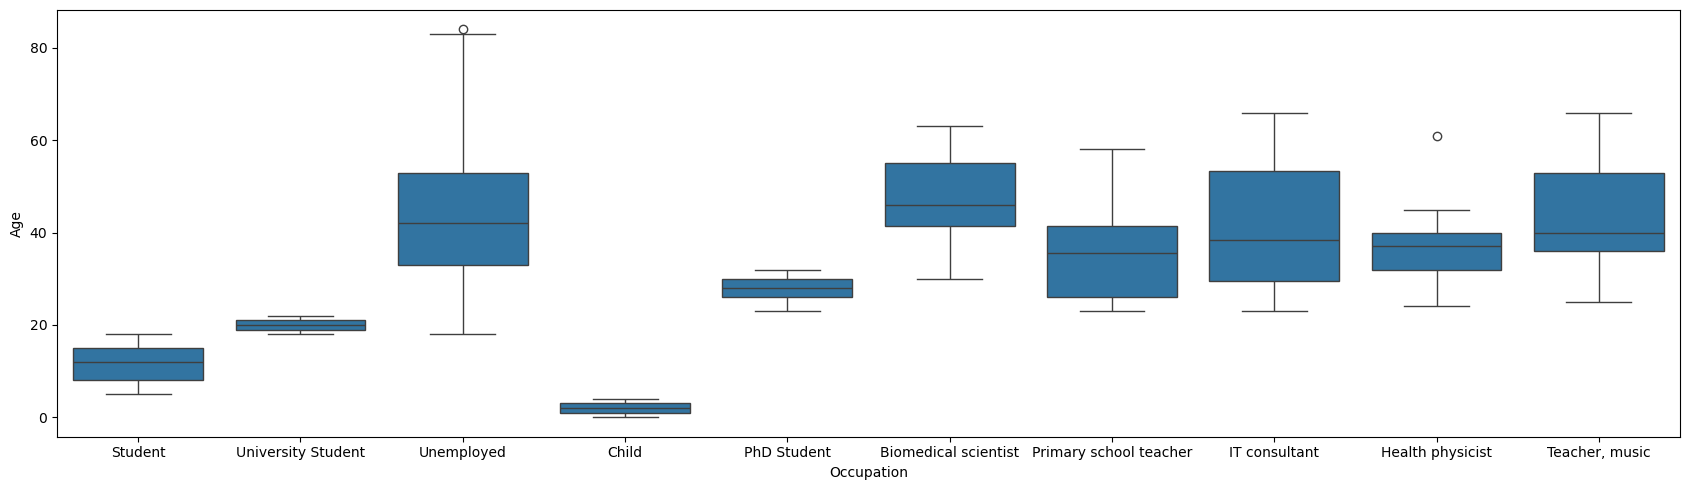

In [200]:
plt.figure(figsize=(17,5))

sns.boxplot(x="Occupation", y="Age", data=data, order=top_10_occupation)

plt.tight_layout()

#relationship between occupation and age using boxplot

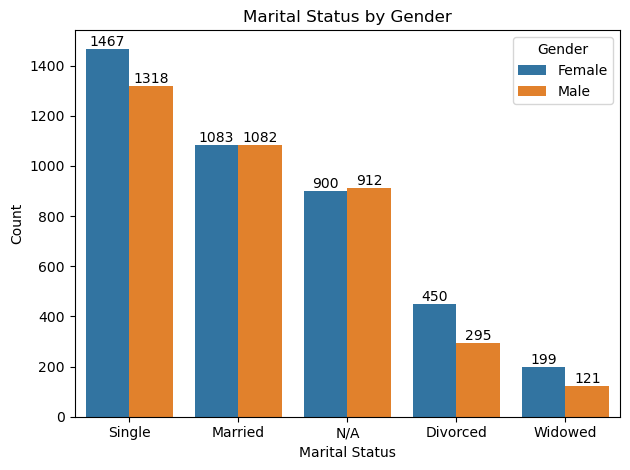

In [201]:
count10 = sns.countplot(x="Marital Status", data=data, hue="Gender", order=data["Marital Status"].value_counts().index)

for i in count10.containers:
    count10.bar_label(i)

plt.title("Marital Status by Gender")
plt.xlabel("Marital Status")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

#bivariate analysis comparing Marital status and gender

## 8a. Recommendation for the Unoccupied Plot of Land

#### Option 1: High-density housing

#### Evidence:

- The dataset contains only one census.
- The dataset does not provide historical population data, so it is not possible to determine whether the population is expanding.

#### Conclusion:

- There is insufficient evidence to conclude that the population is expanding. Therefore, high-density housing cannot be justified from this dataset.

#### Option 2: Low-density housingm

#### Evidence:

- No income, salary, or wealth variables are available.

#### Conclusion:

- The dataset contains no direct indicators of household income or wealth, so there is insufficient evidence to recommend low-density housing based on affluence.
- The dataset does not provide evidence that the population is affluent. Therefore, low-density housing cannot be recommended on this basis.

#### Option 3: Train station

In [202]:
data['Occupation'].value_counts()

Occupation
Student                                            1473
University Student                                  489
Unemployed                                          482
Child                                               477
PhD Student                                          23
                                                   ... 
Retired Designer, graphic                             1
Retired Diplomatic Services operational officer       1
Retired Warden/ranger                                 1
Retired Management consultant                         1
Retired Equities trader                               1
Name: count, Length: 1069, dtype: int64

In [203]:
university_students = (data['Occupation'] == 'University Student').sum()

total_population = len(data)

percentage = (university_students / total_population) * 100

print("University Students:", university_students)
print("Percentage:", percentage)

University Students: 489
Percentage: 6.24760444614795


#### Evidence:

- The town does not have a university, but university students live in the town and commute to nearby cities.
- The dataset contains 489 University Students, representing approximately 6.25% of the total population.
- The occupation data also contains other professional roles that could potentially involve commuting, such as IT consultants, journalists, telecommunications researchers, and retail managers. However, the dataset does not provide workplace locations, so these individuals cannot be confirmed as commuters.

#### Conclusion:

The evidence provides some support for developing a train station. In particular, the 489 university students are identified as commuters because there is no university in the town. However, the dataset does not provide enough information to determine the total number of commuters, since the workplace locations of other residents are unknown. Therefore, the train station is a potential development option, but its priority should be compared with the other proposed developments.

#### Option 4 - Religious building

#### Evidence:

- Christianity is the largest recorded religious category, with 4,435 people, while 3,165 people report no religion.
- The dataset records only 5 people as Catholic and 2 as Church of England, while most Christians are recorded simply as "Christian".
- The town already has a Catholic place of worship, and the dataset does not provide enough information about whether the large "Christian" group requires another church or which denominations they belong to.

#### Conclusion:

The census data does not provide strong evidence that an additional religious building should be prioritised. Although Christianity is the largest religious category, most Christian residents are not assigned a specific denomination in the dataset, making it difficult to determine what type of additional religious building would be required. Therefore, this option is not strongly supported by the available data.

#### Option 5 - Emergency medical building

In [204]:
female_18_44 = data[(data['Gender'] == 'Female') & 
                    (data['Age'].between(18, 44))]

print("Females aged 18-44:", len(female_18_44))

Females aged 18-44: 1788


In [205]:
percentage = (len(female_18_44) / len(data)) * 100

print("Percentage:", round(percentage, 2), "%")

Percentage: 22.84 %


#### Evidence

- 7,724 residents reported no infirmity, while only 103 residents had a recorded infirmity.
- The dataset contains 1,788 females aged 18–44, representing approximately 22.8% of the population.
- The presence of females in this age range indicates a population that could potentially require maternity-related healthcare services, although the dataset does not provide information about actual pregnancies or pregnancy rates.

#### Conclusion

The evidence for an emergency medical building is mixed. The infirmity data does not indicate a large existing burden of reported health conditions, as the vast majority of residents reported no infirmity. However, the town has 1,788 females aged 18–44, meaning there is a sizeable population that could potentially require maternity-related services. Since the dataset does not contain information about actual or expected pregnancies, there is insufficient evidence to make the emergency medical building the strongest recommendation based solely on the census data.

#### Option 6: Something else

#### Evidence

- The census data can be reviewed to identify other significant demographic or social needs not addressed by the previous options.
- However, based on the analyses we have completed so far, we should only propose an alternative development if the data provides clear evidence of a specific unmet need.

#### Conclusion:

No alternative development will be proposed at this stage because the available analyses do not yet provide sufficient evidence for a development outside the five specified options.

In [206]:
development_comparison = pd.DataFrame({
    'Option': [
        'High-density housing',
        'Low-density housing',
        'Train station',
        'Religious building',
        'Emergency medical building',
        'Other development'
    ],
    'Main Evidence': [
        'No historical population data',
        'No income/wealth data',
        '489 University Students',
        '4,435 Christian; 3,165 No Religion',
        '1,788 females aged 18-44',
        'No stronger need was identified'
    ],
    'Assessment': [
        'Insufficient',
        'Insufficient',
        'Strongest',
        'Insufficient',
        'Insufficient',
        'Insufficient'
    ]
})

development_comparison

,Option,Main Evidence,Assessment
0,High-density housing,No historical population data,Insufficient
1,Low-density housing,No income/wealth data,Insufficient
2,Train station,489 University Students,Strongest
3,Religious building,"4,435 Christian; 3,165 No Religion",Insufficient
4,Emergency medical building,"1,788 females aged 18-44",Insufficient
5,Other development,No stronger need was identified,Insufficient


## Final Recommendation for Question (a)

Based on the evidence considered across the different options, I recommend a train station for the unoccupied plot.

The strongest evidence is the 489 University Students, representing 6.25% of the population, who are known to travel outside the town for their studies. The other options require information that is not available in the dataset, such as population growth, income, demand for specific religious facilities or future pregnancy rates.

Therefore, the train station has the clearest evidence-based justification.

# 8B - Priority

#### Option 1 - Employment and training

In [207]:
unemployed = (data['Occupation'] == 'Unemployed').sum()
total_population = len(data)

percentage = (unemployed / total_population) * 100

print("Unemployed:", unemployed)
print("Percentage:", round(percentage, 2), "%")

Unemployed: 482
Percentage: 6.16 %


In [208]:
unemployed_people = data[data['Occupation'] == 'Unemployed']

unemployed_people['Age'].describe()

count    482.000000
mean      43.925311
std       13.428900
min       18.000000
25%       33.000000
50%       42.000000
75%       53.000000
max       84.000000
Name: Age, dtype: float64

#### Evidence

- 482 residents are recorded as unemployed, representing approximately 6.15% of the population.
- The median age of unemployed residents is 42 years, while the middle 50% are aged 33–53 years.
- Unemployment therefore affects a substantial number of adults across working-age groups rather than being limited to very young residents.

#### Conclusion

The census data provides evidence of a need for investment in employment and training. There are 482 unemployed residents, with a median age of 42 years and half of the unemployed population aged between 33 and 53. This suggests that unemployment affects a substantial adult population, making employment and training a potentially important investment for the town.

#### Option 2: Old Age Care

In [209]:
older_people = data[data['Age'] >= 65]

print("People aged 65+:", len(older_people))
print("Percentage:", round((len(older_people) / len(data)) * 100, 2), "%")

People aged 65+: 890
Percentage: 11.37 %


In [210]:
near_retirement = data[data['Age'].between(55, 64)]

print("People aged 55-64:", len(near_retirement))
print("Percentage:", round((len(near_retirement) / len(data)) * 100, 2), "%")

People aged 55-64: 728
Percentage: 9.3 %


#### Option 3: Increase spending for schooling

In [211]:
school_age = data[data['Age'].between(5, 17)]

print("School-aged children:", len(school_age))
print("Percentage:", round((len(school_age) / len(data)) * 100, 2), "%")

School-aged children: 1378
Percentage: 17.61 %


In [212]:
young_children = data[data['Age'].between(0, 4)]

print("Children aged 0-4:", len(young_children))
print("Percentage:", round((len(young_children) / len(data)) * 100, 2), "%")

Children aged 0-4: 477
Percentage: 6.09 %


#### Option 4: General Infastructure

In [213]:
working_age = data[data['Age'].between(18, 64)]

print("Working-age population:", len(working_age))
print("Percentage:", round((len(working_age) / len(data)) * 100, 2), "%")

Working-age population: 5082
Percentage: 64.93 %


In [214]:
households = data.groupby(['Street', 'House Number']).ngroups

print("Number of households:", households)
print("Average people per household:", round(len(data) / households, 2))

Number of households: 2784
Average people per household: 2.81


#### Conclusion

General infrastructure is important because the town contains a large working-age population and 2,784 households. However, the option specifically depends on evidence that the town is expanding. The dataset contains only one census, so population growth cannot be established. Therefore, infrastructure remains important but cannot be identified as the highest investment priority from this dataset.

In [215]:
investment_comparison = pd.DataFrame({
    'Investment Option': [
        'Employment and training',
        'Old-age care',
        'Increase spending for schooling',
        'General infrastructure'
    ],
    'Main Evidence': [
        '482 unemployed',
        '890 aged 65+; 728 aged 55-64',
        '1,855 aged 0-17',
        '5,082 aged 18-64; 2,784 households'
    ],
    'Percentage / Measure': [
        '6.16% unemployed',
        '20.67% aged 55+',
        '23.70% aged 0-17',
        '64.93% working age'
    ],
    'Assessment': [
        'Important need',
        'Important need',
        'Strongest evidence',
        'Important but growth not established'
    ]
})

investment_comparison

,Investment Option,Main Evidence,Percentage / Measure,Assessment
0,Employment and training,482 unemployed,6.16% unemployed,Important need
1,Old-age care,890 aged 65+; 728 aged 55-64,20.67% aged 55+,Important need
2,Increase spending for schooling,"1,855 aged 0-17",23.70% aged 0-17,Strongest evidence
3,General infrastructure,"5,082 aged 18-64; 2,784 households",64.93% working age,Important but growth not established


#### Final Investment Recommendation

Based on the comparison of the four options, I recommend increased spending on schooling.

The strongest evidence comes from the size of the younger population. There are 1,378 residents aged 5–17 and another 477 children aged 0–4, meaning that 1,855 residents, or 23.70% of the population, are under 18.

Old-age care is also important, with 890 residents aged 65+ and a further 728 aged 55–64. Employment and training is supported by 482 unemployed residents, while general infrastructure is clearly important but population expansion cannot be established.

Therefore, schooling has the strongest evidence for investment, while recognising that the dataset cannot prove population growth over time.

### Overall Conclusion

The analysis cleaned and examined the mock census data before using demographic evidence to consider the two local government decisions.

For the unoccupied plot, the strongest option is a **train station**, mainly because 489 University Students (6.25%) are known to travel to nearby cities for their studies.

For investment, **increased spending on schooling** has the strongest supporting evidence. There are 1,378 residents aged 5–17 and 477 children aged 0–4, giving a total of 1,855 residents, or 23.70% of the population, aged under 18.

Other needs were also considered, including unemployment, old-age care, housing, religion, healthcare and general infrastructure. Where the dataset did not contain enough information, such as historical population growth, income, workplace location or actual birth and death rates, conclusions were not made beyond what the data could reasonably support.